# EchoPath — YOLO + Depth Anything V2 **Metric Indoor** Pipeline (HPC / Local GPU)
**Fine-tuned YOLO + DA V2 Metric Indoor Small → Proximity zones (in meters) → Audio alerts**

This notebook is the **metric depth** variant of the pipeline. Unlike the relative-depth version that outputs unitless `0.56` values, this notebook outputs actual distances in meters — e.g., `person | medium | ahead | 2.3m`.

### Important technical note
The HuggingFace depth pipeline returns TWO fields:
- `result['depth']` → a PIL image scaled to 0-255 **for display only** (NOT meters)
- `result['predicted_depth']` → the actual model tensor in meters

This notebook reads `predicted_depth` to get real meter values. Using `depth` here would give you a 0-255 visualization scale that looks like meters but isn't.

### What changed from the relative-depth notebook
- **Cell 3:** loads `Depth-Anything-V2-Metric-Indoor-Small-hf` (same size, ~25MB)
- **Cell 4:** reads `predicted_depth` tensor (in meters) instead of the display image
- **Cell 4:** thresholds are now `1.0m` and `3.0m` (instead of `0.70` / `0.40`)
- **Cell 4:** comparisons flipped (smaller meters = closer)
- **Cell 4:** no more 0–1 normalization — raw output is already in meters
- **Cell 4:** overlay format `d=0.56` → `0.8m`
- **Cell 5:** also reads `predicted_depth`, prints meter values, colormap flipped

Assumes your environment is already set up via `uv` with all dependencies installed (torch, ultralytics, transformers, opencv-python, matplotlib, imageio-ffmpeg).

### Run order
1. Cell 1 — Verify GPU
2. Cell 2 — Set paths
3. Cell 3 — Load models (Metric Indoor variant)
4. Cell 4 — Core pipeline functions (meters)
5. Cell 5 — Depth calibration
6. **Cell 6 — Rotation diagnostic** (run this to pick the right rotation mode)
7. Cell 7 — Process video(s)
8. Cell 8 — Summary


## Cell 1 — Verify GPU

In [9]:
import torch


print(f'PyTorch version : {torch.__version__}')
print(f'CUDA available  : {torch.cuda.is_available()}')
if torch.cuda.is_available():
    print(f'GPU             : {torch.cuda.get_device_name(0)}')
    print(f'VRAM            : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')
else:
    print('WARNING: No GPU detected — pipeline will be very slow on CPU')


PyTorch version : 2.4.1+cu118
CUDA available  : True
GPU             : NVIDIA RTX 4500 Ada Generation
VRAM            : 25.8 GB


## Cell 2 — Set paths (edit these before running anything else)

In [10]:
import os

# ── EDIT THESE BASE PATHS ─────────────────────────────────────────────────────
YOLO_WEIGHTS = r"E:\EchoPath\runs\detect\runs\echopath\v3\weights\best.pt"
VIDEO_DIR    = r"E:\EchoPath\Video_Data"   # drop any video here, it gets picked up automatically
OUTPUT_DIR   = r"E:\EchoPath\Depth Anything Indoor\Output"
# ─────────────────────────────────────────────────────────────────────────────

SUPPORTED_EXTS = {'.mp4', '.avi', '.mov', '.mkv', '.MOV', '.MP4'}

os.makedirs(OUTPUT_DIR, exist_ok=True)
assert os.path.exists(YOLO_WEIGHTS), f'YOLO weights not found: {YOLO_WEIGHTS}'
assert os.path.exists(VIDEO_DIR),    f'Video folder not found: {VIDEO_DIR}'

# Auto-discover all videos in the folder
VIDEO_JOBS = [
    (
        os.path.join(VIDEO_DIR, f),
        os.path.join(OUTPUT_DIR, f"echopath_{f}")
    )
    for f in sorted(os.listdir(VIDEO_DIR))
    if os.path.splitext(f)[1] in SUPPORTED_EXTS
]

assert len(VIDEO_JOBS) > 0, f'No videos found in {VIDEO_DIR}. Supported formats: {SUPPORTED_EXTS}'

print(f'Weights : {YOLO_WEIGHTS}')
print(f'Found {len(VIDEO_JOBS)} video(s) in {VIDEO_DIR}:')
for inp, out in VIDEO_JOBS:
    print(f'  {os.path.basename(inp)}  →  {os.path.basename(out)}')

# TIP: to test on just ONE video first, uncomment the next line:
# VIDEO_JOBS = VIDEO_JOBS[:1]


Weights : E:\EchoPath\runs\detect\runs\echopath\v3\weights\best.pt
Found 13 video(s) in E:\EchoPath\Video_Data:
  Classroom.MP4  →  echopath_Classroom.MP4
  Enterance.MP4  →  echopath_Enterance.MP4
  FDW.mp4  →  echopath_FDW.mp4
  Manthan.mp4  →  echopath_Manthan.mp4
  Persons.mp4  →  echopath_Persons.mp4
  Stairs.MP4  →  echopath_Stairs.MP4
  Water.mp4  →  echopath_Water.mp4
  acad_entry.mp4  →  echopath_acad_entry.mp4
  first_floor.mp4  →  echopath_first_floor.mp4
  lab.mp4  →  echopath_lab.mp4
  sign.mp4  →  echopath_sign.mp4
  trash_bin.mp4  →  echopath_trash_bin.mp4
  water1.mp4  →  echopath_water1.mp4


## Cell 3 — Load models

In [11]:
from ultralytics import YOLO
from transformers import pipeline as hf_pipeline

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Using device: {device}')

# Fine-tuned YOLO
yolo_model = YOLO(YOLO_WEIGHTS)
print('YOLO loaded')

# Depth Anything V2 — METRIC INDOOR variant (outputs depth in meters)
# Fine-tuned on NYU Depth V2 (indoor scenes: rooms, corridors, offices).
# To switch back to relative depth, change model to:
#   'depth-anything/Depth-Anything-V2-Small-hf'
depth_pipe = hf_pipeline(
    task='depth-estimation',
    model='depth-anything/Depth-Anything-V2-Metric-Indoor-Small-hf',
    device=0 if device == 'cuda' else -1
)
print('Depth Anything V2 Metric Indoor Small loaded')


Using device: cuda
YOLO loaded


Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

Depth Anything V2 Metric Indoor Small loaded


## Cell 4 — Core pipeline functions

In [ ]:
import numpy as np
import cv2
from PIL import Image
import imageio_ffmpeg
import subprocess
FFMPEG_EXE = imageio_ffmpeg.get_ffmpeg_exe()

# ── METRIC THRESHOLDS (in meters) ─────────────────────────────────────────────
# Smaller values = closer to camera (opposite of relative depth).
CLOSE_THRESH  = 1.0    # objects within 1 m → 'close'
MEDIUM_THRESH = 3.0    # objects within 1-3 m → 'medium', > 3 m → 'far'
CONF_THRESH   = 0.40   # YOLO confidence threshold
# ─────────────────────────────────────────────────────────────────────────────

def get_video_rotation(video_path):
    """Read rotation metadata. Returns degrees in OpenCV convention (positive = clockwise)."""
    import subprocess, re
    cap = cv2.VideoCapture(video_path)
    try:
        rot = int(cap.get(cv2.CAP_PROP_ORIENTATION_META))
        cap.release()
        if rot != 0:
            return rot
    except Exception:
        cap.release()

    # Fallback: parse ffmpeg. Its displaymatrix uses OPPOSITE sign from OpenCV.
    result = subprocess.run([FFMPEG_EXE, '-i', video_path],
                            capture_output=True, text=True)
    m = re.search(r'displaymatrix:\s*rotation of\s*([+-]?\d+(?:\.\d+)?)\s*degrees',
                  result.stderr)
    if m:
        ff_rot = int(float(m.group(1)))
        return (-ff_rot) % 360 if ff_rot != 0 else 0

    m = re.search(r'rotate\s*:\s*([+-]?\d+)', result.stderr)
    if m:
        return int(m.group(1)) % 360

    return 0


def fix_rotation(frame, rotation):
    """Rotate frame. `rotation` is in OpenCV convention (positive = clockwise)."""
    rotation = rotation % 360
    if rotation == 90:
        return cv2.rotate(frame, cv2.ROTATE_90_CLOCKWISE)
    elif rotation == 180:
        return cv2.rotate(frame, cv2.ROTATE_180)
    elif rotation == 270:
        return cv2.rotate(frame, cv2.ROTATE_90_COUNTERCLOCKWISE)
    return frame


def get_depth_and_zone(depth_map, bbox, frame_width):
    """Extract avg depth (meters) within a bounding box, map to proximity zone + direction."""
    x1, y1, x2, y2 = map(int, bbox)
    region = depth_map[y1:y2, x1:x2]
    if region.size == 0:
        return 0.0, 'far', 'ahead'
        

    avg_depth = float(np.percentile(region,30))   # meters

    # METRIC: smaller distance = closer
    if avg_depth < CLOSE_THRESH:
        proximity = 'close'
    elif avg_depth < MEDIUM_THRESH:
        proximity = 'medium'
    else:
        proximity = 'far'

    cx = (x1 + x2) / 2
    third = frame_width / 3
    if cx < third:
        direction = 'left'
    elif cx < 2 * third:
        direction = 'ahead'
    else:
        direction = 'right'

    return avg_depth, proximity, direction


def generate_alerts(detections):
    """Only alert for close/medium objects; close-proximity alerts come first."""
    alerts = [d for d in detections if d['proximity'] in ('close', 'medium')]
    alerts.sort(key=lambda d: 0 if d['proximity'] == 'close' else 1)
    return alerts


def process_frame(frame):
    """Run full EchoPath pipeline on one frame (metric depth variant)."""
    h, w = frame.shape[:2]

    # YOLO detection
    results = yolo_model.predict(frame, conf=CONF_THRESH, verbose=False)[0]

    # Depth estimation — IMPORTANT: use 'predicted_depth' tensor (actual meters)
    # NOT result['depth'] which is just a 0-255 visualization PIL image.
    pil_img = Image.fromarray(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    result  = depth_pipe(pil_img)
    pred    = result['predicted_depth']
    raw_depth = pred.squeeze().cpu().numpy().astype(np.float32)

    # Resize to frame dimensions — keep meter values intact
    depth_map = cv2.resize(raw_depth, (w, h))

    # Fusion — combine YOLO boxes with depth map
    detections = []
    for box in results.boxes:
        bbox      = box.xyxy[0].cpu().numpy()
        label     = yolo_model.names[int(box.cls[0])]
        conf      = float(box.conf[0])
        avg_depth, proximity, direction = get_depth_and_zone(depth_map, bbox, w)
        detections.append(dict(label=label, bbox=bbox, conf=conf,
                               depth=avg_depth, proximity=proximity,
                               direction=direction))

    alerts = generate_alerts(detections)

    # Annotate frame — overlay reads "1.8m" instead of "d=0.56"
    annotated = frame.copy()
    COLOR = {'close': (0, 0, 255), 'medium': (0, 165, 255), 'far': (0, 200, 0)}
    for d in detections:
        x1, y1, x2, y2 = map(int, d['bbox'])
        c   = COLOR[d['proximity']]
        txt = f"{d['label']} | {d['proximity']} | {d['direction']} | {d['depth']:.1f}m"
        cv2.rectangle(annotated, (x1, y1), (x2, y2), c, 2)
        cv2.putText(annotated, txt, (x1, y1 - 8),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, c, 2)

    return annotated, alerts, depth_map


print('Pipeline functions ready! (metric depth, meters)')


Pipeline functions ready! (metric depth, meters)


## Cell 5 — Depth calibration helper
**Run this before Cell 7.** It samples one frame and prints depth statistics so you can set the right thresholds in Cell 4.


Calibration frame from: Classroom.MP4

Depth map stats (meters):
  closest point  = 0.77 m
  farthest point = 4.27 m
  mean distance  = 1.97 m
  median         = 1.56 m

Current thresholds (in meters):
  CLOSE_THRESH  = 1.0   (< 1 m = close)
  MEDIUM_THRESH = 3.0   (1-3 m = medium, > 3 m = far)

If your corridors are consistently shorter or longer, adjust in Cell 4.


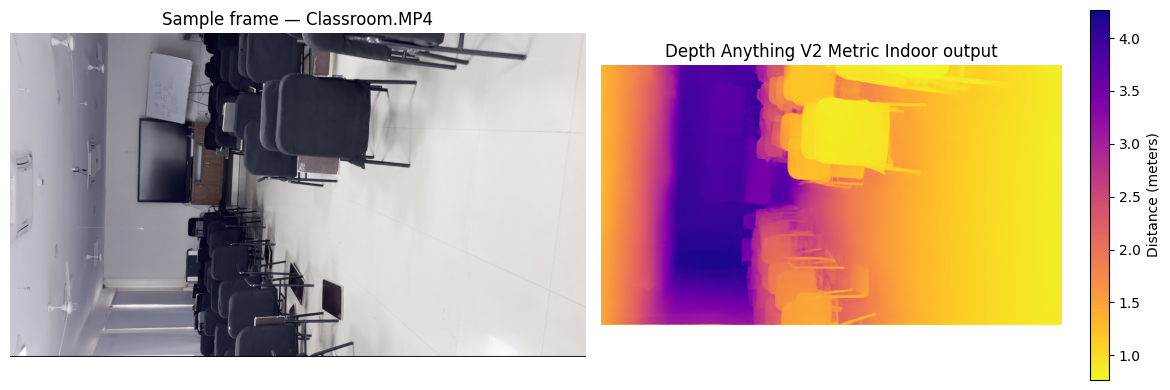

Depth map saved to: E:\EchoPath\Depth Anything Indoor\Output\depth_metric_calibration.png


In [13]:
import matplotlib.pyplot as plt

SAMPLE_FRAME = 30
SAMPLE_VIDEO = VIDEO_JOBS[0][0]

cap = cv2.VideoCapture(SAMPLE_VIDEO)
for _ in range(SAMPLE_FRAME):
    ret, frame = cap.read()
    if not ret:
        break
cap.release()

# NOTE: this preview does NOT apply manual rotation — on modern OpenCV the
# frame comes out correctly oriented. If the preview looks rotated, see Cell 6.

# IMPORTANT: read 'predicted_depth' (meters), NOT 'depth' (which is 0-255 display)
pil_img = Image.fromarray(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
result  = depth_pipe(pil_img)
pred    = result['predicted_depth']
raw     = pred.squeeze().cpu().numpy().astype(np.float32)

print(f'Calibration frame from: {os.path.basename(SAMPLE_VIDEO)}')
print()
print('Depth map stats (meters):')
print(f'  closest point  = {raw.min():.2f} m')
print(f'  farthest point = {raw.max():.2f} m')
print(f'  mean distance  = {raw.mean():.2f} m')
print(f'  median         = {np.median(raw):.2f} m')
print()
print('Current thresholds (in meters):')
print(f'  CLOSE_THRESH  = 1.0   (< 1 m = close)')
print(f'  MEDIUM_THRESH = 3.0   (1-3 m = medium, > 3 m = far)')
print()
print('If your corridors are consistently shorter or longer, adjust in Cell 4.')

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
plt.title(f'Sample frame — {os.path.basename(SAMPLE_VIDEO)}')
plt.axis('off')
plt.subplot(1, 2, 2)
# plasma_r: reversed so bright = close, dark = far (matches intuition in meters)
plt.imshow(raw, cmap='plasma_r')
plt.colorbar(label='Distance (meters)')
plt.title('Depth Anything V2 Metric Indoor output')
plt.axis('off')
plt.tight_layout()

calib_path = os.path.join(OUTPUT_DIR, 'depth_metric_calibration.png')
plt.savefig(calib_path, dpi=120)
plt.show()
print(f'Depth map saved to: {calib_path}')


## Cell 6 — Rotation diagnostic (run this once per dataset)

**What this does:** shows you what OpenCV delivers when reading a frame. Modern OpenCV (≥ 4.5) auto-rotates using video metadata; older versions don't. This cell tells you which case you're in.

**How to read the output:**
- Frame looks **right-side up** → leave `USE_OPENCV_AUTO_ROTATE = True` in Cell 7 ✓
- Frame looks **upside down or sideways** → set `USE_OPENCV_AUTO_ROTATE = False` in Cell 7


OpenCV orientation metadata : 90.0°
OpenCV auto-rotate enabled  : False
ffmpeg-reported rotation    : 90°
Frame shape as delivered    : (1080, 1920, 3)  (H, W, C)


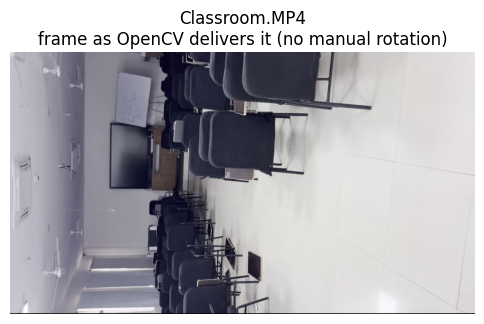


────────────────────────────────────────────────────────────
DECISION:
  If the image above is CORRECTLY oriented → Cell 7: USE_OPENCV_AUTO_ROTATE = True
  If the image above is ROTATED/UPSIDE-DOWN → Cell 7: USE_OPENCV_AUTO_ROTATE = False
────────────────────────────────────────────────────────────


In [14]:
test_video = VIDEO_JOBS[0][0]
cap = cv2.VideoCapture(test_video)

try:
    meta_rot = cap.get(cv2.CAP_PROP_ORIENTATION_META)
    auto = cap.get(cv2.CAP_PROP_ORIENTATION_AUTO)
    print(f'OpenCV orientation metadata : {meta_rot}°')
    print(f'OpenCV auto-rotate enabled  : {bool(auto)}')
except Exception as e:
    print(f'Orientation props unavailable: {e}')

ffmpeg_rot = get_video_rotation(test_video)
print(f'ffmpeg-reported rotation    : {ffmpeg_rot}°')

ret, frame = cap.read()
print(f'Frame shape as delivered    : {frame.shape}  (H, W, C)')
cap.release()

plt.figure(figsize=(6, 10))
plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
plt.title(f'{os.path.basename(test_video)}\nframe as OpenCV delivers it (no manual rotation)')
plt.axis('off')
plt.show()

print()
print('─' * 60)
print('DECISION:')
print('  If the image above is CORRECTLY oriented → Cell 7: USE_OPENCV_AUTO_ROTATE = True')
print('  If the image above is ROTATED/UPSIDE-DOWN → Cell 7: USE_OPENCV_AUTO_ROTATE = False')
print('─' * 60)


## Cell 7 — Process video(s)

Based on Cell 6's diagnostic, set `USE_OPENCV_AUTO_ROTATE`:
- `True` (default) if Cell 6 showed the frame correctly oriented
- `False` if the frame was rotated


In [15]:
import subprocess

PROCESS_EVERY_N = 2

# ── ROTATION MODE ─────────────────────────────────────────────────────────────
# True  = trust OpenCV's built-in rotation handling (modern OpenCV 4.5+).
# False = disable OpenCV auto-rotate and apply rotation manually from metadata.
# Set this based on what Cell 6 showed you.
USE_OPENCV_AUTO_ROTATE = True
# ─────────────────────────────────────────────────────────────────────────────

all_jobs_log = {}
FFMPEG_EXE = imageio_ffmpeg.get_ffmpeg_exe()
print(f'Using ffmpeg: {FFMPEG_EXE}')
print(f'OpenCV auto-rotate: {USE_OPENCV_AUTO_ROTATE}\n')

for job_idx, (INPUT_VIDEO, OUTPUT_VIDEO) in enumerate(VIDEO_JOBS):
    vname = os.path.basename(INPUT_VIDEO)
    print(f'{"="*60}')
    print(f'[{job_idx+1}/{len(VIDEO_JOBS)}] Processing: {vname}')
    print(f'{"="*60}')

    cap = cv2.VideoCapture(INPUT_VIDEO)

    # Explicitly set OpenCV's auto-rotation behavior
    try:
        cap.set(cv2.CAP_PROP_ORIENTATION_AUTO, 1 if USE_OPENCV_AUTO_ROTATE else 0)
    except Exception:
        pass

    # Decide what rotation WE still need to apply
    if USE_OPENCV_AUTO_ROTATE:
        manual_rotation = 0            # OpenCV already did it
    else:
        manual_rotation = get_video_rotation(INPUT_VIDEO)
    print(f'  Manual rotation to apply: {manual_rotation}°')

    # Probe one frame to get the TRUE delivered dimensions
    ret, probe = cap.read()
    if not ret:
        print('  Could not read frame, skipping.')
        cap.release()
        continue
    probe = fix_rotation(probe, manual_rotation)
    out_h, out_w = probe.shape[:2]
    cap.set(cv2.CAP_PROP_POS_FRAMES, 0)   # rewind

    fps   = cap.get(cv2.CAP_PROP_FPS)
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    print(f'  Output size: {out_w}x{out_h} @ {fps:.1f} fps  |  {total} frames')

    tmp_out = OUTPUT_VIDEO.replace('.mp4', '_tmp.mp4')
    writer  = cv2.VideoWriter(tmp_out, cv2.VideoWriter_fourcc(*'mp4v'),
                              fps, (out_w, out_h))

    frame_idx      = 0
    prev_alert     = ''
    alert_log      = []
    last_annotated = None

    while cap.isOpened():
        ret, frame = cap.read()
        if not ret:
            break
        frame = fix_rotation(frame, manual_rotation)   # no-op when auto-rotate is on

        if frame_idx % PROCESS_EVERY_N == 0:
            annotated, alerts, _ = process_frame(frame)
            last_annotated = annotated

            if alerts:
                alert_txt = f"{alerts[0]['label']} {alerts[0]['proximity']} {alerts[0]['direction']}"
                if alert_txt != prev_alert:
                    print(f'  [Frame {frame_idx:>5}] ALERT: {alert_txt}')
                    alert_log.append((frame_idx, alert_txt))
                    prev_alert = alert_txt
            else:
                prev_alert = ''

            writer.write(annotated)
        else:
            writer.write(last_annotated if last_annotated is not None else frame)

        frame_idx += 1
        if frame_idx % 200 == 0:
            print(f'  {frame_idx}/{total} frames processed...')

    cap.release()
    writer.release()

    ffmpeg_result = subprocess.run(
        [FFMPEG_EXE, '-y',
         '-noautorotate',
         '-i', tmp_out,
         '-vcodec', 'libx264',
         '-crf', '23',
         '-metadata:s:v', 'rotate=0',
         OUTPUT_VIDEO],
        capture_output=True, text=True
    )
    if ffmpeg_result.returncode == 0:
        os.remove(tmp_out)
        print(f'  Saved (h264): {OUTPUT_VIDEO}')
    else:
        os.rename(tmp_out, OUTPUT_VIDEO)
        print(f'  ffmpeg error — saved raw: {OUTPUT_VIDEO}')
        print(ffmpeg_result.stderr[-300:])

    all_jobs_log[vname] = alert_log
    print(f'  Unique alerts: {len(alert_log)}\n')

print(f'{"="*60}')
print(f'All {len(VIDEO_JOBS)} videos done. Outputs in: {OUTPUT_DIR}')


Using ffmpeg: e:\EchoPath\.venv\Lib\site-packages\imageio_ffmpeg\binaries\ffmpeg-win-x86_64-v7.1.exe
OpenCV auto-rotate: True

[1/13] Processing: Classroom.MP4
  Manual rotation to apply: 0°
  Output size: 1080x1920 @ 30.0 fps  |  566 frames
  [Frame    82] ALERT: chair medium right
  [Frame   102] ALERT: chair medium left
  [Frame   126] ALERT: chair medium left
  [Frame   134] ALERT: chair medium left
  [Frame   140] ALERT: chair medium left
  [Frame   154] ALERT: chair medium left
  [Frame   156] ALERT: chair medium ahead
  [Frame   160] ALERT: chair medium ahead
  [Frame   166] ALERT: chair medium ahead
  [Frame   168] ALERT: chair medium left
  [Frame   172] ALERT: chair medium ahead
  [Frame   176] ALERT: chair medium left
  [Frame   188] ALERT: chair medium ahead
  [Frame   196] ALERT: chair medium left
  200/566 frames processed...
  [Frame   210] ALERT: chair medium left
  [Frame   216] ALERT: chair medium left
  [Frame   248] ALERT: chair medium ahead
  [Frame   256] ALERT: c

## Cell 8 — Video summary

In [16]:
for vname, log in all_jobs_log.items():
    inp_path = os.path.join(VIDEO_DIR, vname)
    cap_tmp  = cv2.VideoCapture(inp_path)
    fps_tmp  = cap_tmp.get(cv2.CAP_PROP_FPS)
    cap_tmp.release()
    print(f'\n── {vname} ({len(log)} unique alerts) ──')
    for frame_n, txt in log:
        ts = frame_n / fps_tmp if fps_tmp > 0 else 0
        print(f'  [{ts:6.2f}s | Frame {frame_n:>5}]  {txt}')



── Classroom.MP4 (34 unique alerts) ──
  [  2.73s | Frame    82]  chair medium right
  [  3.40s | Frame   102]  chair medium left
  [  4.20s | Frame   126]  chair medium left
  [  4.47s | Frame   134]  chair medium left
  [  4.67s | Frame   140]  chair medium left
  [  5.13s | Frame   154]  chair medium left
  [  5.20s | Frame   156]  chair medium ahead
  [  5.33s | Frame   160]  chair medium ahead
  [  5.53s | Frame   166]  chair medium ahead
  [  5.60s | Frame   168]  chair medium left
  [  5.73s | Frame   172]  chair medium ahead
  [  5.87s | Frame   176]  chair medium left
  [  6.27s | Frame   188]  chair medium ahead
  [  6.53s | Frame   196]  chair medium left
  [  7.00s | Frame   210]  chair medium left
  [  7.20s | Frame   216]  chair medium left
  [  8.27s | Frame   248]  chair medium ahead
  [  8.53s | Frame   256]  chair medium right
  [  8.60s | Frame   258]  chair medium left
  [  8.87s | Frame   266]  chair medium ahead
  [  9.40s | Frame   282]  chair medium left
  [ 11